In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [8]:
df1 = pd.read_csv("mrc_table1.csv", usecols=["super_opeid", "trend_parq1", "trend_bottom40"])
df2 = pd.read_csv("mrc_table2.csv")

merged_mrc = df2.merge(df1, on="super_opeid", how="inner")

# Drop rows where super_opeid is less than 0
merged_mrc = merged_mrc[merged_mrc["super_opeid"] >= 0]

merged_mrc.to_csv("merged_mrc.csv", index=False)

In [10]:
df = pd.read_csv("merged_mrc.csv", usecols=["tier", "par_q1", "par_q5"]).dropna()
df["gap"] = df["par_q5"] - df["par_q1"]


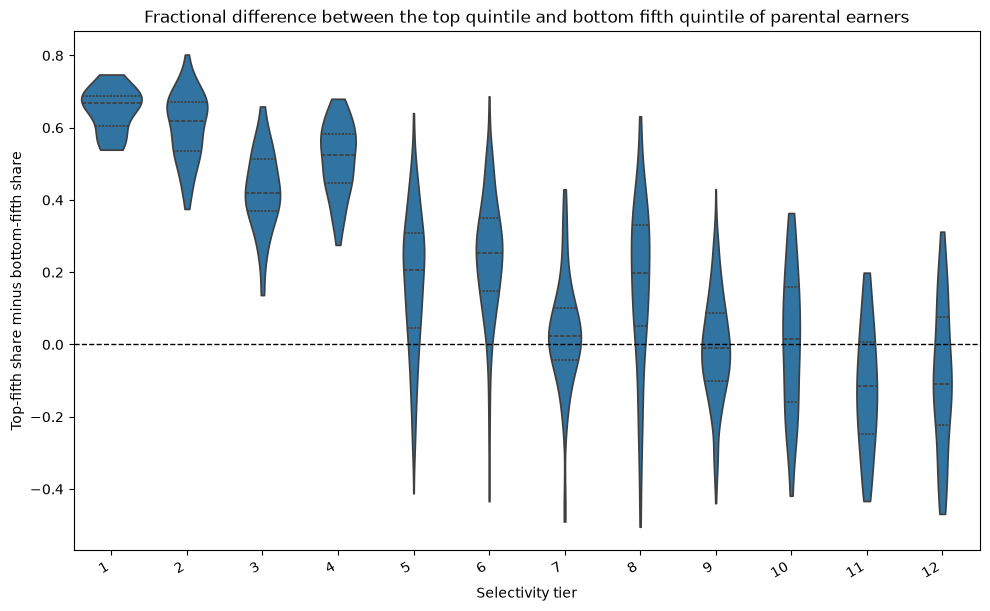

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(data=df, x="tier", y="gap", inner="quartile", cut=0, ax=ax)
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_ylabel("Top-fifth share minus bottom-fifth share")
ax.set_xlabel("Selectivity tier")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.title("Fractional difference between the top quintile and bottom fifth quintile of parental earners")
plt.show()